# 01 · When is withdrawal actually established?
### A source-linked evidence workbench for revocation in delegated workflows

**Node & Norm · Private research draft · 6 November 2026**

A caller receives “accepted.” Has authority changed? A caller remains unconfirmed. Can an effect still happen? This notebook makes those questions inspectable through twelve saved cases, with the source record one step away from every interpretation.

**Start here:** [Question](#question) → [Workflow](#workflow) → [Evidence](#evidence) → [Case explorer](#case-explorer) → [Challenge claims](#challenge) → [Decision brief](#brief) → [Audit](#audit)

| Read | Explore | Review |
| --- | --- | --- |
| 5 minutes: question, matrix, S2/S4/S5, brief | 15 minutes: change the scope and case cells; rerun downstream cells | Inspect exact source excerpts, input hashes, raw JSON, tests and limitations |

**Saved preview:** outputs in GitHub show the committed default selection. GitHub does not run controls. In a local Python 3.10+ Jupyter kernel, use **Restart Kernel and Run All** to recompute; no network, API key, model, package installation or live Temporal service is needed. A standard-library, fresh-process verification command is also provided in [the notebook guide](README.md).

This notebook re-reads saved evidence. It does not rerun the historical experiment, turn an AI-assisted audit into human validation, or qualify Temporal native execution.

<a id="question"></a>
## 1 · Fix the question before opening the evidence

**Bounded research question:** What can the saved request-to-fence cases establish separately about request acceptance, fence installation, caller confirmation and protected effects within the recorded observation window?

**Decision this supports:** Can a researcher trace those distinctions to preserved evidence without confusing receipt, enforcement and caller knowledge?

**Stop condition:** Every selected case resolves to pinned evidence and agrees with the retained summary on the fields used here. Missing required inputs, byte mismatches, ambiguous members, or failures in the selected consistency checks stop the workflow before a brief is assembled. This is not exhaustive semantic validation of the original instrument. A failed counterexample search remains unresolved; it never becomes proof.

**Scope:** direct reference and native framework checkpoint/resume paths; schedules S0–S5; one authority, one delegation edge, one trusted local sink. The framework path is the earlier checkpoint/resume implementation, **not Temporal**. The two paths share the authority mechanism.

<a id="workflow"></a>
## 2 · See the implemented workflow

The course's [full-agent notebook](https://github.com/langchain-ai/deep_research_from_scratch/blob/main/notebooks/5_full_agent.ipynb) and [architecture](https://github.com/langchain-ai/deep_research_from_scratch/blob/main/src/deep_research_from_scratch/research_agent_full.py) inspired the progression: scope → inspect the workflow → run a concrete example → examine the report and trace.

Here the implementation is a **deterministic local Python workflow**, with six real stages and a fail-closed evidence gate. It does not instantiate LangGraph, delegate to model agents, retrieve from the web, compress away source records or call a report-writing model. A future LangGraph adapter would need its own approved implementation and evaluation. The diagram below describes the functions that run today.

### Adapt the course without overstating the implementation

The uploaded **Deep Research From Scratch** overview deck was also reviewed. All six uploaded PDF copies were byte-identical, so they are treated as one 14-slide reference, not six independent lesson decks.

| Course stage | Working counterpart here | Boundary |
| --- | --- | --- |
| Clarification → research brief (slide 9) | Explicit bounded question, validated path/schedule selection and stop condition | No conversational model clarification |
| Research agent: LLM ↔ tools; MCP variant (slide 10) | Pinned local source lookup, exact excerpts and raw-record access | No LLM tool loop or live MCP connection |
| Supervisor: Topics → researchers → Findings (slide 11) | Named review responsibilities and source-linked handoffs below | No runtime supervisor or parallel model workers |
| One-Shot Report Generation (slide 12) | Deterministic brief after integrity, reconciliation and counterexample checks | Synthesis is a derivative, never a replacement for evidence |
| Evaluate sub-components (slide 13) | Separate tests for loading, selectors, reconciliation, rendering and abstention | No end-to-end research-quality or reviewer-benefit evaluation |

The deck's historical benchmark screenshot concerns a different deep-research system; it is not evidence about this tutorial repository, this notebook or revocation enforcement. No benchmark claim is transferred.


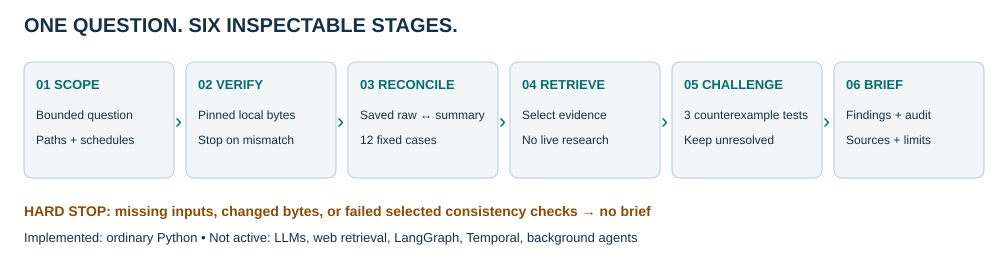

In [1]:
from pathlib import Path
import json
import sys

# Run from the repository root or notebooks/. No installation or environment secrets.
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / "docs/research-records/v0.1/source_manifest.json").is_file()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook inside the complete repository checkout.")
sys.dont_write_bytecode = True
if str(ROOT / "notebooks") not in sys.path:
    sys.path.insert(0, str(ROOT / "notebooks"))

from workbench.core import Scope, EvidenceError, run_workbench, barrier_rows, ARCHIVE, CHECKER
from workbench.presentation import (
    show, workflow_map, overview, glossary_view, source_inventory, case_matrix,
    claim_view, barrier_view, raw_json, excerpt, table, brief_view,
)
show(workflow_map())

### Choose a bounded evidence slice

These are Python controls, not decorative widgets. Edit the cell and rerun it plus the cells below. The defaults select the complete twelve-case matrix. For a focused comparison, try `paths=("direct",)` and `schedules=("S2", "S4", "S5")`. Set `Scope()` to reset.

The notebook still verifies and reconciles the full twelve-case saved collection before filtering. Selection changes the displayed evidence and counterexample results; it cannot grant access or change the sources. This is an analyst workbench, not a blinded reviewer packet or an access-control boundary.

In [2]:
scope = Scope(paths=("direct", "framework"), schedules=("S0", "S1", "S2", "S3", "S4", "S5"))
run = run_workbench(ROOT, scope)
evidence = run.evidence
show(overview(run))

Saved cases,Effects,Revoked denials,Fenced cases,Post-fence effects
12,6,6,8,0


<a id="evidence"></a>
## 3 · Establish the evidence boundary

The workflow uses the existing source manifest, glossary and evidence registry. It also opens the preserved study ZIP **in memory**, reads the twelve exact `measured01/{path}/{schedule}/record.json` members and recomputes selected summary fields. Nothing is extracted or executed from the archive.

The new [input manifest](workbench/input_manifest.json) pins every file used, including source archives, current-status documentation and the synthetic checker example. The ten original source snapshots are checked again against their original manifest. Source-reference keys must resolve to the retained manifest, and locator text must be nonempty. The code does not parse free-text section locators; inspect the source excerpt to check their meaning.

**What the check means:** selected saved JSON fields agree with the retained summary. It does not independently reopen historical SQLite databases, replay the historical checker, authenticate the producer, or establish complete recording beyond the source's declared boundary.

In [3]:
show(table(["Gate", "Result"], [
    ["Pinned input files", f"{len(evidence.receipts)} / {len(evidence.receipts)} byte matches"],
    ["Original source snapshots", f"{len(evidence.sources)} / {len(evidence.sources)} byte matches"],
    ["Saved raw / summary reconciliation", f"{len(evidence.rows)} / {len(evidence.rows)} cases agree on selected fields"],
    ["New runtime observations", "0 — this is saved-evidence review"],
], title="Evidence gate completed"))

Gate,Result
Pinned input files,76 / 76 byte matches
Original source snapshots,10 / 10 byte matches
Saved raw / summary reconciliation,12 / 12 cases agree on selected fields
New runtime observations,0 — this is saved-evidence review


In [4]:
show(table(["Request acceptance", "Fence installation", "Caller confirmation"],
           [["Relay reports volatile receipt; caller remains PENDING.",
             "Trusted sink commits the authority change.",
             "Caller validates a matching completion envelope."]],
           title="Three facts • three evidence channels",
           note="Notebook interpretation in brief. Exact source definitions and forbidden inferences appear in the source appendix."))

Request acceptance,Fence installation,Caller confirmation
Relay reports volatile receipt; caller remains PENDING.,Trusted sink commits the authority change.,Caller validates a matching completion envelope.


### Source passports

The registry is a **4 November snapshot**, not a current oracle. Its claims, statuses, uncertainty and AI-use fields remain intact. Later implementation history appears separately in section 7.

The `temporal_status` source is an explicitly disclosed derivative: private conversation identifiers and authorization context were removed before it entered the repository. The original and derivative hashes remain in the source manifest. This notebook neither restores nor copies that private context.

## 4 · Read the full case pattern

The table below is generated from the selected raw records. **No fence in the window** differs from an installed fence with zero later effects. The historical summary stores `post_fence_effect_count=0` in both situations; the workbench shows **N/A** for no-fence cases and leaves the original bytes untouched.

S0 is a live control with an **IDLE** caller and no withdrawal request. It must not be relabeled “unconfirmed.”

In [5]:
show(case_matrix(run.rows))

Path / case,Acceptance,Sink fence,Caller,Effect / denial,After fence
direct / S0,none,none in window,IDLE (no request),effect: 7,N/A — no fence
direct / S1,volatile,seq 7,CONFIRMED,denied: revoked,0
direct / S2,volatile,seq 9,CONFIRMED,effect: 7,0
direct / S3,volatile,seq 7,CONFIRMED,denied: revoked,0
direct / S4,volatile,seq 7,UNCONFIRMED at window end,denied: revoked,0
direct / S5,volatile,none in window,UNCONFIRMED at window end,effect: 7,N/A — no fence
framework / S0,none,none in window,IDLE (no request),effect: 7,N/A — no fence
framework / S1,volatile,seq 7,CONFIRMED,denied: revoked,0
framework / S2,volatile,seq 9,CONFIRMED,effect: 7,0
framework / S3,volatile,seq 7,CONFIRMED,denied: revoked,0


<a id="case-explorer"></a>
## 5 · Inspect one case, then test the decisive contrast

**Explorer control:** choose `CASE_PATH` and `CASE_SCHEDULE`, then rerun the next cell. It is independent of the matrix filter so you can inspect any of the twelve saved cases. Unknown values fail visibly.

The diagram uses **saved barrier capture order**, not elapsed time or invented request timestamps. It shows the caller state, committed fence sequence and cumulative effects at each retained capture. Caller and sink are different evidence channels, placed together here for analyst review.

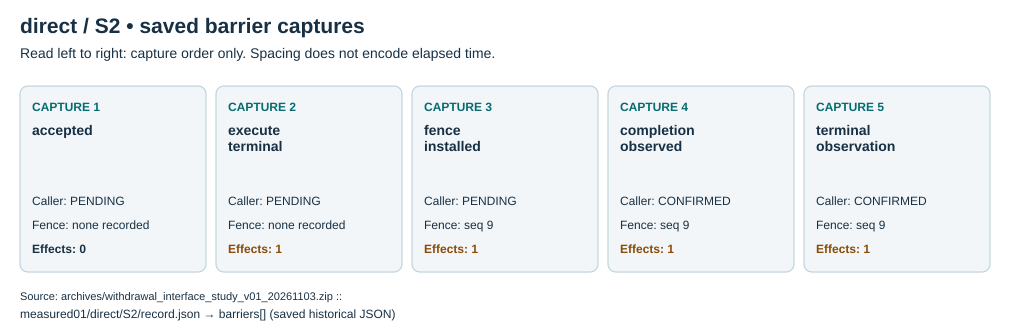

In [6]:
CASE_PATH = "direct"       # "direct" or "framework"
CASE_SCHEDULE = "S2"      # "S0" ... "S5"
selected_case = evidence.case(CASE_PATH, CASE_SCHEDULE)
show(barrier_view(selected_case))

**Default example: S2 (this explanation stays fixed when you change the explorer).** acceptance leaves the caller PENDING while the sink still permits an effect. The saved sink records effect sequence 7 before revocation sequence 9. Later confirmation does not erase that effect. This is a selected deterministic schedule, not an estimate of race probability.

The following table exposes the exact fields behind the selected diagram. Change the explorer control to see another case.

In [7]:
captures = barrier_rows(selected_case)
show(table(["Capture", "Barrier", "Caller state", "Fence seq", "Effects"],
           [[b["capture"], b["barrier"], b["caller"], b["fence"], b["effects"]] for b in captures],
           title=f"Exact selected fields • {CASE_PATH}/{CASE_SCHEDULE}"))

Capture,Barrier,Caller state,Fence seq,Effects
1,accepted,PENDING,None,0
2,execute_terminal,PENDING,None,1
3,fence_installed,PENDING,9,1
4,completion_observed,INSTALLED_CONFIRMED,9,1
5,terminal_observation,INSTALLED_CONFIRMED,9,1


### Same caller uncertainty, different sink reality

S4 and S5 both reach `UNCONFIRMED_AT_OBSERVATION_END`. S4 records a fence and a revoked denial; S5 records no fence and one effect in the window. This comparison uses the selected explorer path and fixed schedules S4/S5, regardless of the matrix filter. Withholding is deliberate relay behavior, not observed packet loss or crash recovery.

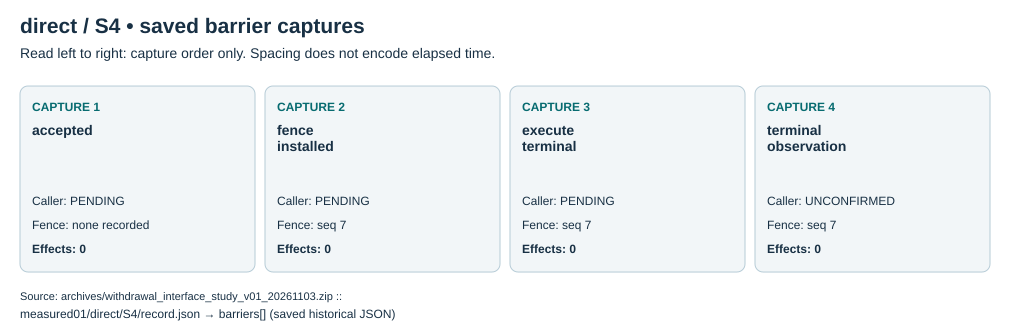

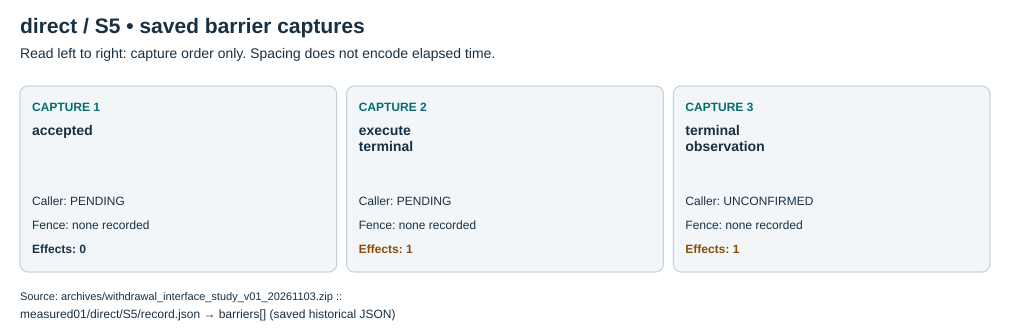

In [8]:
for schedule in ("S4", "S5"):
    show(barrier_view(evidence.case(CASE_PATH, schedule)))

### Inspect the source before trusting the interpretation

The caller transitions below are **source JSON values**, displayed without summarization. The locator identifies the exact archive member and field. The complete record, including sink events and barrier snapshots, is available as `selected_case`; it is not hidden behind a generated report.

In [9]:
show(raw_json(selected_case["caller_trace"], "Source JSON • caller_trace",
              f"{ARCHIVE} :: measured01/{CASE_PATH}/{CASE_SCHEDULE}/record.json → caller_trace"))

Source JSON • caller_trace
archives/withdrawal_interface_study_v01_20261103.zip :: measured01/direct/S2/record.json → caller_trace
[
  {
    "input": {
      "kind": "issue",
      "request_id": "withdrawal-1"
    },
    "before": "IDLE",
    "after": "PENDING"
  },
  {
    "input": {
      "kind": "accepted_volatile",
      "request_id": "withdrawal-1"
    },
    "before": "PENDING",
    "after": "PENDING"
  },
  {
    "input": {
      "kind": "completion",
      "request_id": "withdrawal-1",
      "root": "rootR",
      "withdrawn_epoch": 7,
      "new_epoch": 8,
      "status": "installed",
      "scope": "single_local_sink",
      "gateway_response": {
        "outcome": "revocation",
        "root": "rootR",
        "withdrawn_epoch": 7,
        "new_epoch": 8
      }
    },
    "before": "PENDING",
    "after": "INSTALLED_CONFIRMED"
  }
]

<a id="challenge"></a>
## 6 · Challenge plausible overclaims

These three tests search the **selected matrix rows** for counterexamples. They are explicit predicates in [the core module](workbench/core.py), not an LLM fact-checker. A counterexample refutes the stated implication in these records. No counterexample in a narrow selection means **unresolved**, not true.

Try selecting only S0 and rerunning from the scope cell: all three claims should remain unresolved. Restore `Scope()` to return to the complete evidence.

In [10]:
show(table(["Claim", "Proposition under test", "Result", "Witnesses"],
           [[c["claim_id"], c["proposition"], c["status"], ", ".join(c["witnesses"]) or "none in selection"]
            for c in run.challenges], title="Fixed counterexample queries"))

Claim,Proposition under test,Result,Witnesses
C1,Unconfirmed at observation end means no fence was installed.,counterexample in selected records,"direct/S4, framework/S4"
C2,Unconfirmed at observation end means a fence was installed.,counterexample in selected records,"direct/S5, framework/S5"
C3,Caller confirmation means no effect occurred in the window.,counterexample in selected records,"direct/S2, framework/S2"


### Follow a claim back to the original registry

Change `CLAIM_QUERY` to a literal term such as `fence`, `Temporal` or `current_gate`. An empty string resets to all ten records. This filter searches the entire original registry, independently of the case selection; no hit means no matching registry text, not no evidence.

In [11]:
CLAIM_QUERY = "confirmation_not_sink_reality"
show(claim_view(evidence.source_claims(CLAIM_QUERY)))

Record,Historical claim (verbatim),Historical status,Source / locator
confirmation_not_sink_reality,"S4 and S5 both end unconfirmed, while S4 has a fence and revoked denial, and S5 has no fence and one effect in the window.",supported by preserved result summary and audit,withdrawal_summary: rows schedule=S4 and S5; withdrawal_review: Outcomes


In [12]:
SOURCE_KEY = "withdrawal_review"
START_LINE = 1
LINE_COUNT = 22
show(excerpt(evidence, SOURCE_KEY, START_LINE, LINE_COUNT))

Source excerpt • withdrawal_review • lines 1–22
docs/review/WITHDRAWAL_INTERFACE_POSTRUN_REVIEW_v0.1.md
# Independent post-run review

Audit time: 2026-11-03 19:16 UTC. Scope: the separately authorized measured campaign under frozen_candidate_v02, not additional workflow execution.

## Verdict

All 12 measured cases pass the independently executed frozen checker against their raw SQLite sink databases. The direct and native paths each include exactly S0–S5. All records identify themselves as measured. No missing case, unexpected effect, wrong request identity, unsupported completion claim, missing native outcome or frozen-source hash mismatch was found.

All six native cases use distinct initial and resumed process IDs, preserve their exact checkpoint and interrupt/action identities, and propagate the actual sink result to the final supervisor message. Independently opened checkpoint databases contain the recorded initial and final checkpoint IDs. Standalone worker_pause.json and worker_resume.json exactly match their embedded record artifacts.

## Outcomes

Both paths reproduce the registered outcomes:

- S0: one authorized effect, caller IDLE.
- S1: revoked denial, no effect, caller installation confirmed before resume.
- S2: one pre-fence effect remains recorded after installation confirmation.
- S3: revoked denial while caller remains pending, followed by installation confirmation when the response is delivered.
- S4: revoked denial and no effect, but caller remains unconfirmed at observation end because completion is withheld.
- S5: one authorized effect with no delivered withdrawal/fence in the observation window; caller remains unconfirmed.

The total of six effects is expected: three in each path. Six resumed attempts are denied as revoked. Live controls succeed, so safe denials are not credited to an absent execution path. A confirmed fence does not imply rollback of S2's historical effect.

## 7 · Keep historical status separate from current status

The 4 November registry describes an independent checker as outstanding. On 5 November, the repository added an **artifact-only synthetic checker prototype**. The original assertion remains useful history, but it is not a complete present-tense account.

The [dated overlay](workbench/status_overlay.json) links that change without rewriting any historical record. It does **not** upgrade the blocked native qualification. The reported 115 project tests and 26 separately authored regression tests are engineering checks, not independent empirical observations or human validation.

In [13]:
overlay = evidence.overlays["entries"][0]
show(table(["Layer", "Account"], [
    ["Historical registry", "2026-11-04: unchecked_success and current_gate retain their original claims and limits."],
    ["Later implementation", overlay["current_account"]],
    ["Still open", overlay["remaining_gap"]],
    ["Source locator", overlay["source_path"] + " → " + overlay["locator"]],
], title="Dated interpretation overlay • as of " + evidence.overlays["as_of_utc_date"]))

Layer,Account
Historical registry,2026-11-04: unchecked_success and current_gate retain their original claims and limits.
Later implementation,"An artifact-only synthetic checker prototype was added on 2026-11-05. Its reported 115 project tests and 26 separately authored regression tests are engineering checks, not measured Temporal observations. Native qualification remains blocked."
Still open,"Production export/adapters, independently persisted runtime phase registries, observed native mappings, calibrated deadlines and native measurement readiness remain open."
Source locator,docs/checker-implementation/2026-11-05/README.md → What passed and what remains open; Preservation and chronology


### Run the existing checker on one explicitly synthetic bundle

This cell calls the already-tested repository module on `fixtures/case_001`. That bundle is **synthetic-only** and is not part of the historical twelve-case collection. It reads saved local files; it does not start a service, Worker, gateway or socket. The complete returned report is available as `synthetic_report`.

The result is useful precisely because the checker keeps artifact integrity and native qualification separate. A successful function call is not a scientific pass.

In [14]:
checker_source = ROOT / CHECKER / "src"
if str(checker_source) not in sys.path:
    sys.path.insert(0, str(checker_source))
from temporal_checker.engine import check_bundle

synthetic_report = check_bundle(ROOT / CHECKER / "fixtures/case_001")
assert synthetic_report["evidence_class"] == "synthetic_only"
assert synthetic_report["native_qualification"] is False
show(table(["Field", "Actual checker output"], [
    ["evidence_class", synthetic_report["evidence_class"]],
    ["native_qualification", synthetic_report["native_qualification"]],
    ["checker_version", synthetic_report["checker_version"]],
], title="Separate synthetic example • never pooled with historical cases",
   note="The complete report remains in synthetic_report. No live Temporal execution occurred."))

Field,Actual checker output
evidence_class,synthetic_only
native_qualification,False
checker_version,0.1.0


<a id="brief"></a>
## 8 · Assemble a bounded decision brief

The brief below depends on the current case selection and the counterexample queries. It is ordinary Python synthesis over preserved source-linked values. It carries its evidence boundary and uncertainty alongside the finding.

In [15]:
show(brief_view(run))

Decision brief,Account
Scope,"12 selected saved cases; paths=('direct', 'framework'); schedules=('S0', 'S1', 'S2', 'S3', 'S4', 'S5')"
Derived accounting,6 effects; 6 revoked denials; 0 post-fence effects in 8 fenced cases.
Counterexamples,"C1: direct/S4, framework/S4; C2: direct/S5, framework/S5; C3: direct/S2, framework/S2"
Evidence boundary,Recomputed selected facts from preserved JSON; summary agreement checked. Historical execution and full checker audit not rerun.
Temporal status,"Synthetic artifact-only prototype exists; native qualification remains blocked, no measured Temporal result."
Limits,scripted model responses; trusted single local sink; one root and one edge; one outstanding withdrawal; relay withholding is deliberate; no crash recovery or distributed closure; no statistical reliability or novelty claim
Next decision,"Review this interface and source traceability. No new native experiment, API call, public release or claim of reviewer benefit is enabled."


<a id="audit"></a>
## 9 · Inspect the audit and the stop behavior

This trace is generated by the executed workflow. It records what was actually checked, rather than a decorative list of agent roles. Exact input receipts remain available as `evidence.receipts`, and each source's full digest and locator remain in `evidence.sources`.

The tests also exercise changed, missing and ambiguous inputs, summary/raw disagreement, unsafe paths, invalid/empty filters and counterexample abstention. They operate on temporary copies or in-memory records and do not modify historical evidence.

In [16]:
show(table(["Stage", "Outcome", "Detail"],
           [[a["stage"], a["outcome"], a["detail"]] for a in run.audit],
           title="Actual workflow audit"))
try:
    Scope(schedules=("S99",))
except EvidenceError as exc:
    print("Expected stop for invalid selection:", exc)
else:
    raise AssertionError("Invalid selection was not stopped")

Stage,Outcome,Detail
scope,bounded,2 paths × 6 schedules
verify,matched,76 input files; 10 source snapshots
reconcile,matched,12 raw JSON cases agree with selected summary fields
retrieve,selected,12 saved cases; no new observations
challenge,evaluated,3 fixed counterexample queries
brief,assembled,"Derived facts, source links, uncertainty and dated status overlay"


Expected stop for invalid selection: Unknown schedules: ('S99',); allowed: ('S0', 'S1', 'S2', 'S3', 'S4', 'S5')


### Source appendix · exact definitions and complete inventory

These source-linked tables support close review after the main case comparison. The glossary wording below is verbatim. All ten source snapshots remain distinct from the notebook's interpretations.


In [17]:
show(glossary_view(evidence))

Term,Source definition (verbatim),Does not imply (verbatim)
Request accepted,The relay reports volatile receipt of the sole pending withdrawal request. The caller remains PENDING.,"Fence installation, durable receipt, restart recovery, caller installation confirmation, or prevention of an effect."
Fence installed,The trusted local sink has committed the fixture authority change from active epoch 7 to epoch 8/inactive.,Caller has learned of installation; rollback of past effects; cessation of all computation; distributed closure.
Caller confirmation,The caller validates a matching completion envelope and records INSTALLED_CONFIRMED within its finite observation window.,Authenticated generic receipt; arbitrary target enforcement by the unchanged gateway; effect rollback.
Protected effect,An inert protected operation is committed to the trusted synthetic sink under the exact operation/effect identity.,Activity or Workflow completion; caller knowledge; physical or production action.
Unconfirmed at observation end,"At the declared observation-end signal, a caller still in PENDING transitions to UNCONFIRMED_AT_OBSERVATION_END because no valid matching completion has been received within that window. This does not describe IDLE or INVALID_RESPONSE.",Fence absent or present. S4 has a fence and S5 lacks one within the window.


In [18]:
show(source_inventory(evidence))

Source key,Kind,Repository locator,SHA-256 (prefix)
reconciliation,current source review,docs/research-records/v0.1/sources/reconciliation.md,ce9ff80337554432
temporal_contract,proposed contract,docs/review/TEMPORAL_STATUS_EVIDENCE_CONTRACT_v01.md,b65e6422f80c4e44
temporal_status,partial execution status,docs/research-records/v0.1/sources/temporal_status.md,de63522cf6db0d16
runtime_setup,setup report,archives/temporal_qualification_partial_20261104.zip :: temporal_qualification_partial_20261104/runtime_setup/QUALIFICATION_SUMMARY.md,2b0df6c1b1457228
withdrawal_protocol,historical protocol; later result status supersedes drafting status,docs/review/WITHDRAWAL_INTERFACE_PROTOCOL_v0.1.md,fdf9c7e0190ff39b
withdrawal_summary,historical result summary,docs/review/WITHDRAWAL_INTERFACE_SUMMARY_v0.1.json,273d485b72bc2332
withdrawal_review,historical AI-assisted audit report,docs/review/WITHDRAWAL_INTERFACE_POSTRUN_REVIEW_v0.1.md,98dc38ffa7fada19
methods_review,independent AI-assisted source review,docs/review/TEMPORAL_METHODS_REVIEW_20261104.md,ab6001b2d6c56b04
schema_log,schema-only test log,archives/temporal_qualification_partial_20261104.zip :: temporal_qualification_partial_20261104/bridge_qualification/logs/q1_schema.txt,118c3ab1a6b77c17
blocked_control_log,failed bridge control log,archives/temporal_qualification_partial_20261104.zip :: temporal_qualification_partial_20261104/bridge_qualification/logs/q2.txt,36d3bcc5c99375dd


## 10 · Use it with the research team

Mark leads the research and approves consequential next steps. **alfred** coordinates assignments and brings the evidence and unresolved questions back for review. The notebook is a shared work surface for the team's AI-assisted roles, assigned as needed:

| Role | Use this notebook for | Reviewable handoff |
| --- | --- | --- |
| **SORA** · Source and Original Research Analysis | Inspect source passports, exact excerpts and historical/current status | Source key + exact locator + scope + uncertainty; preserve source wording |
| **MIRA** · Methods, Investigation and Review Assistant | Inspect case selection, barrier captures, counterexamples and tests | Method challenge + decisive record + what the selected evidence cannot establish |
| **TRACE** · Traceability, Review, Assurance and Claim Examination | Check claim/source links, hashes, status overlays and brief wording | Claim audit + provenance gap + unresolved or corrected status |
| **Future roles** | Unassigned until a concrete need and scope are agreed | Explicit assignment and permission boundaries before work |

These are responsibilities for review and handoff, not connected agent processes or a persistent autonomous team. A notebook run does not summon SORA, MIRA or TRACE, use external models or grant new permissions. The research team's [charter](../docs/team/CHARTER.md) and [assignment workflow](../docs/team/WORKFLOW.md) provide the broader operating context.

## 11 · What this first notebook establishes

- **Implemented now:** scoped local retrieval, input integrity checks, twelve-case saved JSON reconciliation, case/barrier views, literal registry search, source excerpts, three counterexample queries, one separate synthetic checker call, a bounded brief and execution audit.
- **Not established:** producer authenticity, complete raw-database regrading, a new experimental replication, statistical reliability, production readiness, distributed closure, arbitrary crash recovery, reviewer speed or quality benefits, a novel general control principle, or AGI safety.
- **Not implemented:** a persistent research team runtime, live research tools, LLM synthesis, LangGraph orchestration, stable study-wide ID migration, graph usefulness evaluation, native Temporal qualification or a measured Temporal comparison.

**Review request:** Does this view make the distinction between acceptance, fence and confirmation easy to inspect without weakening the evidence boundary? Useful changes should improve that task before expanding into a larger system.

**Possible next notebooks, still proposed:** evidence-view comparison with equal-access baselines; observation cuts and contradiction handling; a separately approved qualification-to-measurement gate. The existing [later-stage design notes](../docs/research-records/v0.1/LATER_STAGES.md) remain proposals.

### Provenance and authorship

AI assisted this notebook's code, analysis, tests and editorial design. Separate AI-assisted review is not human validation. The course was consulted as a structural reference, not used as evidence for revocation claims; no course code or image was copied. Reference notebook blob: `cb62a5d8593e7ede7c90b67976b5a9f31d0ca8ab`; architecture blob: `6e30ed3a511900911764a5861ee40147494a98ed`.

Historical inputs are pinned to repository baseline `6a2d6b19e18df28e2a8e69ee45830a5f9b94f26c`. Original sources, archives, claims and result files remain unchanged. See [verification and reproduction](README.md) for what was checked and the distinction between fresh-process validation and a Jupyter-kernel run.

[Back to the question](#question) · [Case explorer](#case-explorer) · [Decision brief](#brief)